In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

In [3]:
billboard = pd.read_csv('data/billboard.csv')

In [4]:
# setting up model
target = "weeks_at_number_one"
X = billboard.drop(columns=[target, "non_consecutive"])
y = billboard[target]
num_cols = X.select_dtypes(include=["int64", "float64"]).columns
cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns

C:\Users\Izzy\AppData\Local\Temp\ipykernel_12272\926969646.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns


In [5]:
# preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), num_cols),
        (
            "cat",
            Pipeline(
                steps=[
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("encoder", OneHotEncoder(handle_unknown="ignore")),
                ]
            ),
            cat_cols,
        ),
    ]
)

In [6]:
# combine model and preprocessor
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=200,
                max_depth=10,
                min_samples_leaf=3,
                random_state=42,
                n_jobs=-1,
            ),
        ),
    ]
)

In [7]:
# splitting data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
model.fit(X_train, y_train)

# make predictions, get evaluation metrics
y_pred = model.predict(X_test)
print(f"MAE: {mean_absolute_error(y_test, y_pred):.2f} weeks")
print(f"RMSE: {root_mean_squared_error(y_test, y_pred):.2f} weeks")

MAE: 1.76 weeks
RMSE: 2.52 weeks


In [8]:
# calculating feature importance
preprocessor = model.named_steps["preprocessor"]
encoded_importances = model.named_steps["regressor"].feature_importances_
importances_by_variable = dict(
    zip(num_cols, encoded_importances[preprocessor.output_indices_["num"]])
)
categorical_importances = encoded_importances[preprocessor.output_indices_["cat"]]
encoder = preprocessor.named_transformers_["cat"].named_steps["encoder"]
offset = 0
for variable, categories in zip(cat_cols, encoder.categories_):
    width = len(categories)
    importances_by_variable[variable] = categorical_importances[offset : offset + width].sum()
    offset += width

importances = pd.Series(importances_by_variable).nlargest(20).sort_values()

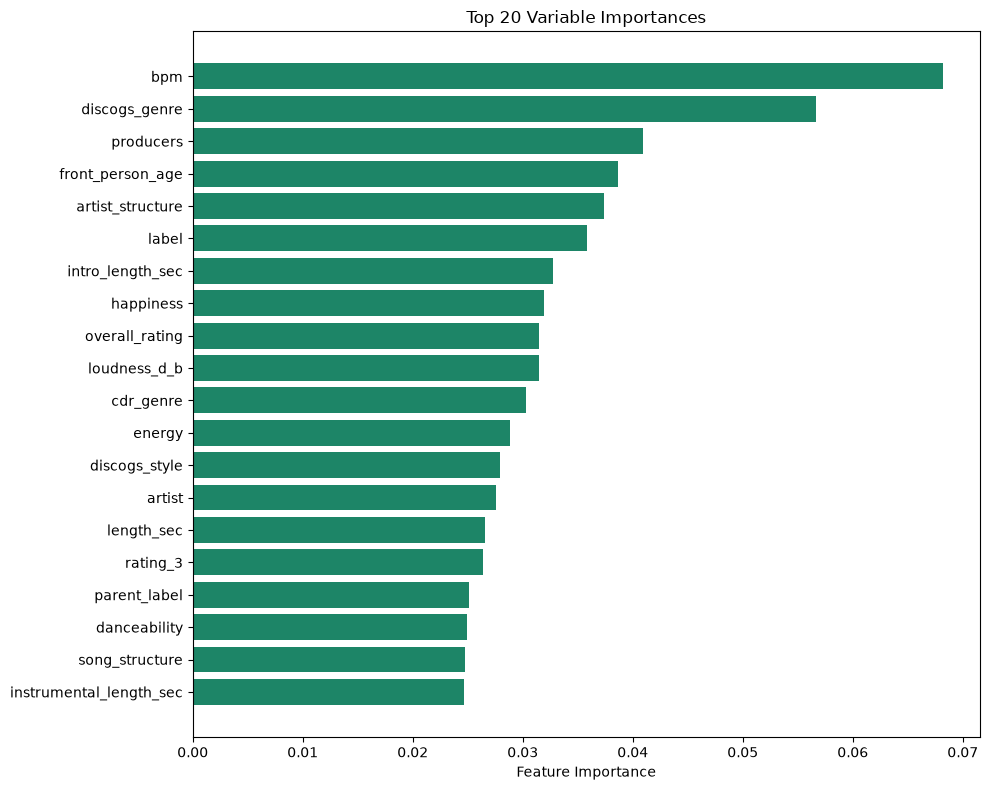

In [9]:
#plot feature importance
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(importances.index.astype(str), importances.to_numpy(dtype=float), color="#1d8567")
ax.set_xlabel("Feature Importance")
ax.set_title("Top 20 Variable Importances")
fig.tight_layout()
plt.show()

In [10]:
# calculating prediction differences
weeks_test_results = pd.DataFrame(
    {
        "song": X_test["song"],
        "date": pd.to_datetime(X_test["date"], utc=True),
        "actual_weeks_at_number_one": y_test,
        "predicted_weeks_at_number_one": y_pred,
    }
).sort_values("date")
weeks_test_results["difference_weeks"] = (
    weeks_test_results["actual_weeks_at_number_one"] - weeks_test_results["predicted_weeks_at_number_one"]
)
weeks_at_number_one_difference = weeks_test_results["difference_weeks"]

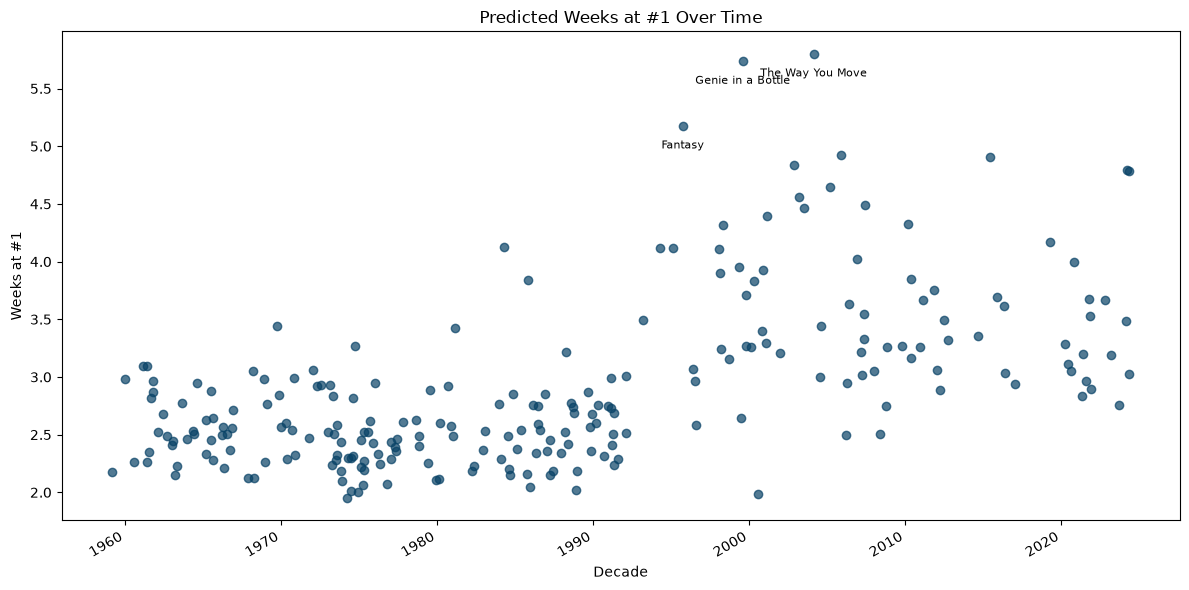

In [16]:
#plotting predicted weeks at #1
fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(
    weeks_test_results["date"],
    weeks_test_results["predicted_weeks_at_number_one"],
    alpha=0.7,
    color="#084266"
)
for _, song in weeks_test_results.loc[weeks_test_results["predicted_weeks_at_number_one"] > 5].iterrows():
    ax.annotate(
        song["song"],
        xy=(song["date"], song["predicted_weeks_at_number_one"]),
        xytext=(0, -10),
        textcoords="offset points",
        ha="center",
        va="top",
        fontsize=8,
    )
ax.set_xlabel("Decade")
ax.set_ylabel("Weeks at #1")
ax.set_title("Predicted Weeks at #1 Over Time")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

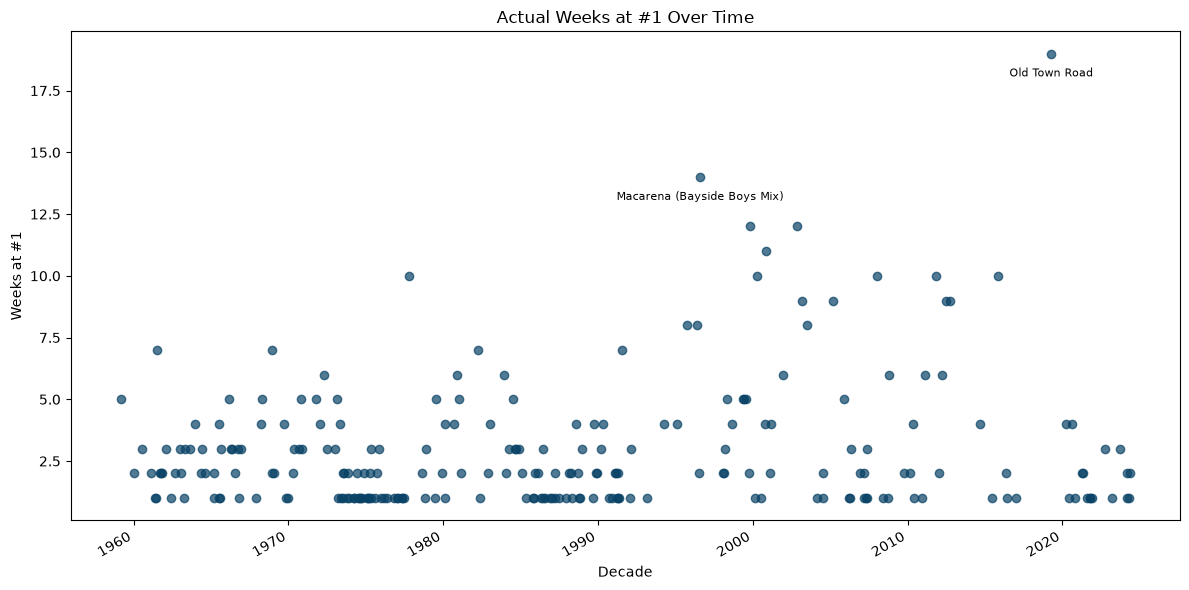

In [17]:
#plotting actual weeks at #1
fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(
    weeks_test_results["date"],
    weeks_test_results["actual_weeks_at_number_one"],
    alpha=0.7,
    color="#084266"
)
for _, song in weeks_test_results.loc[weeks_test_results["actual_weeks_at_number_one"] > 13].iterrows():
    ax.annotate(
        song["song"],
        xy=(song["date"], song["actual_weeks_at_number_one"]),
        xytext=(0, -10),
        textcoords="offset points",
        ha="center",
        va="top",
        fontsize=8,
    )

ax.set_xlabel("Decade")
ax.set_ylabel("Weeks at #1")
ax.set_title("Actual Weeks at #1 Over Time")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

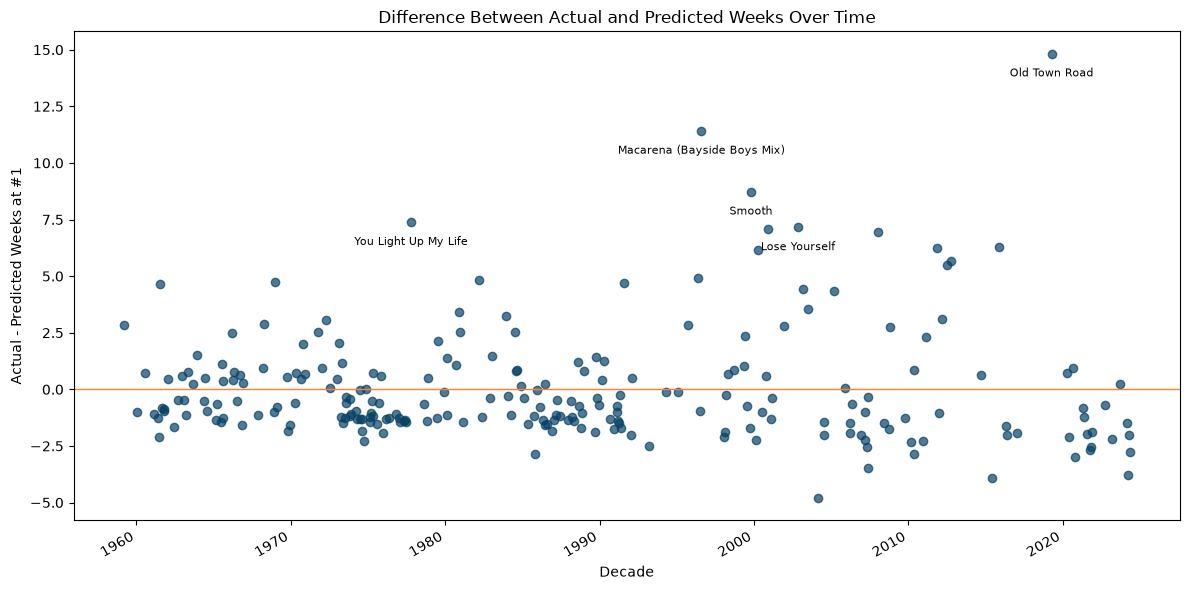

In [23]:
#plotting prediction differences
fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(weeks_test_results["date"], weeks_at_number_one_difference, alpha=0.7, color="#084266")
for _, song in weeks_test_results.loc[weeks_test_results["difference_weeks"] > 7].iterrows():
    if song["song"] == "Independent Women, Part 1":
        continue
    ax.annotate(
        song["song"],
        xy=(song["date"], song["difference_weeks"]),
        xytext=(0, -10),
        textcoords="offset points",
        ha="center",
        va="top",
        fontsize=8,
    )
ax.axhline(0, color="#fe7f2d", linewidth=1)
ax.set_xlabel("Decade")
ax.set_ylabel("Actual - Predicted Weeks at #1")
ax.set_title("Difference Between Actual and Predicted Weeks Over Time")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

Findings:

The model tends to predict safely, with most of it's predictions being between 1 and 5 weeks, which makes sense because that's how long most #1 hits stay at that spot. It also has a hard time predicting when songs stay at #1 for a long time. I was very interested to see that starting in the 1995/2000 range, it got more lenient with the predictions. I imagine this might be because before that, songs tended to have much shorter durations at #1. 